# Ji et al. 2020 — Cutaneous SCC
## 03 · Embryonic-module signatures

Gast (gastrulation), pSom (posterior somitogenesis), Crest (neural crest) scored with the union control pool; signature UMAPs match the reference plotting style.

In [1]:
import os, sys, re, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Ji2020_Skin-2  (attempt suffix)
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition (Skin)
dset = re.sub(r'-\d+$', '', name)                       # strip -N attempt suffix -> input folder key
pth  = os.path.join(*([os.pardir] * 6))                 # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dset)                                # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)            # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
FEAT = os.path.join(pth_data, 'features', 'biomart')
print('dataset:', name, '| category:', cat)

dataset: Ji2020_Skin-2 | category: Skin


In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
print(adata)

AnnData object with n_obs × n_vars = 7085 × 21042
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'leiden', 'cycling', 'compartment', 'GSE162534', 'GSE229103', 'rRNAModifications', 'Gast', 'pSom', 'Crest', 'Gast_sm', 'pSom_sm', 'Crest_sm', 'lz', 'zG', 'zP', 'zC', 't', 'seg', 'edge', 'milestones'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'cell_subtype_level1_colors', 'celltype_colors', 'graph', 'leiden', 'leiden_colors', 'log1p', 'lz', 'milestones_colors', 'neighbors', 'pca', 'ppt', 'pseudotime_list', 'sample_colors', 'seg_colors', 'umap'
    obsm: 'X_R', 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'


### Score modules (union control pool) + smoothed geography

In [4]:
feat_fn = sorted(glob.glob(os.path.join(FEAT, '*.csv')))
get_src = lambda fn: os.path.basename(fn).replace('.csv','')
get_feat = lambda fn: pd.read_csv(fn).hsapiens.drop_duplicates().dropna()
feat_dict = {get_src(fn): get_feat(fn) for fn in feat_fn}
g_ref = feat_dict['union'][feat_dict['union'].isin(adata.var_names)]
for src, df_src in feat_dict.items():
    if src == 'union': continue
    g = df_src[df_src.isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=src, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print('%s: %d / %d genes recovered (control pool %d)' % (src, g.size, df_src.size, g_ref.size))
adata.obs['Gast'] = adata.obs.GSE162534; adata.obs['pSom'] = adata.obs.GSE229103; adata.obs['Crest'] = adata.obs.rRNAModifications
A = adata.obsp['connectivities']; deg = np.asarray(A.sum(1)).ravel(); deg[deg==0]=1
for k in ['Gast','pSom','Crest']:
    adata.obs[k+'_sm'] = (A @ adata.obs[k].values) / deg

GSE162534: 76 / 81 genes recovered (control pool 224)
GSE229103: 88 / 98 genes recovered (control pool 224)
rRNAModifications: 101 / 104 genes recovered (control pool 224)


### Signature geography over the tree — Gate 2
Gast and pSom peak on **different** arms out of the hub (cross-repression axis); Crest is high at an arm tip (terminal readout), enriched on the pSom arm. **Gate 2 GO (branching).**

per-role smoothed module means + mean pseudotime:
          Gast_sm  pSom_sm  Crest_sm       t
celltype                                    
Gast_arm   -0.019    0.029     0.027   7.995
Mixed      -0.002    0.061     0.006   0.402
pSom_arm   -0.037    0.061     0.015  10.891


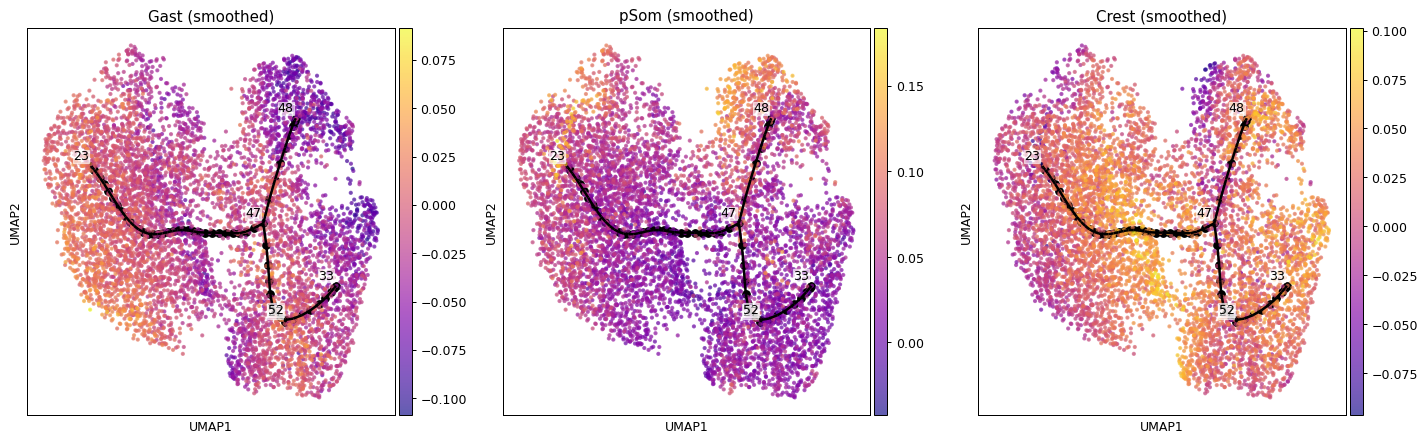

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
for ax, c in zip(axs, ['Gast_sm','pSom_sm','Crest_sm']):
    scf.pl.graph(adata, basis='umap', ax=ax, show=False)
    sc.pl.umap(adata, color=c, ax=ax, show=False, size=45, cmap='plasma', alpha=.65)
    ax.set_title(c.replace('_sm',' (smoothed)'))
plt.tight_layout(); plt.show()
print('per-role smoothed module means + mean pseudotime:')
print(adata.obs.groupby('celltype', observed=True)[['Gast_sm','pSom_sm','Crest_sm','t']].mean().round(3).to_string())

### `Gast_signature.pdf` (+ colorbar)

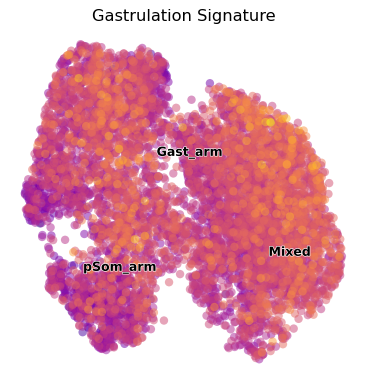

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='GSE162534', cmap='plasma', alpha=.5, size=180, colorbar_loc=None,
           frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=180, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Gastrulation Signature', size=13)
fig.savefig(os.path.join(pth_fig, 'Gast_signature.pdf'), bbox_inches='tight'); plt.show()

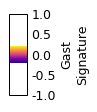

In [7]:
fig = plt.figure(figsize=(.66, 1)); cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
cb.set_label('Gast\nSignature'); ticks = np.asarray([-1,-.5,0,.5,1])
cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'Gast_colorbar.pdf'), bbox_inches='tight'); plt.show()

### `pSom_signature.pdf` (+ colorbar)

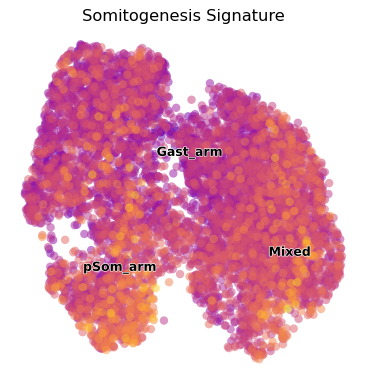

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='GSE229103', cmap='plasma', alpha=.5, size=180, colorbar_loc=None,
           frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=180, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Somitogenesis Signature', size=13)
fig.savefig(os.path.join(pth_fig, 'pSom_signature.pdf'), bbox_inches='tight'); plt.show()

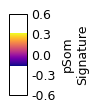

In [9]:
fig = plt.figure(figsize=(.66, 1)); cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
cb.set_label('pSom\nSignature'); ticks = np.asarray([-.6,-.3,0,.3,.6])
cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'pSom_colorbar.pdf'), bbox_inches='tight'); plt.show()

### `Crest_signature.pdf` (+ colorbar)

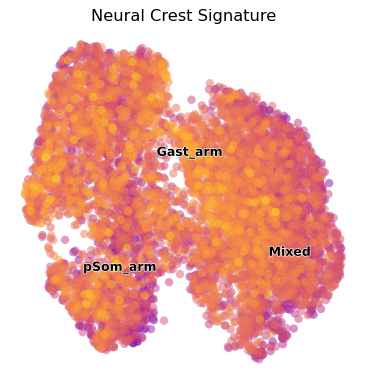

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='rRNAModifications', cmap='plasma', alpha=.5, size=180, colorbar_loc=None,
           frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=180, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Neural Crest Signature', size=13)
fig.savefig(os.path.join(pth_fig, 'Crest_signature.pdf'), bbox_inches='tight'); plt.show()

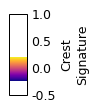

In [11]:
fig = plt.figure(figsize=(.66, 1)); cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
cb.set_label('Crest\nSignature'); ticks = np.asarray([-.5,0,.5,1])
cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'Crest_colorbar.pdf'), bbox_inches='tight'); plt.show()

In [12]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (7085, 21042)
